In [1]:
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath('')), 'Utilities'))
import numpy as np
import matplotlib.pyplot as plt
import spiderman as sp
import batman
import hyperillumination_utils as hi
import hyperillumination_phasecurve_utils as hipc
import kepler_utils as k 
import batman_utils

looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.02                                   #planet radius [stellar radii / rs]
rs = 0.68                                   #stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = k.AU_to_RS(a_AU, rs)                    #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

In [3]:
lambda_range = [4e-6, 5e-6] # wavelength range of detector [m]
# ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)

## Thermal Phasecurve from Custom Spiderman brightness map (Hyperillumination)

### Build and verify the (lo, la, T) grid from `insolation_kopal`

In [4]:
lo, la, temp_grid = hipc.custom_temperature_grid(rp, 1, a, T_eff, insolation_model = "kopal")

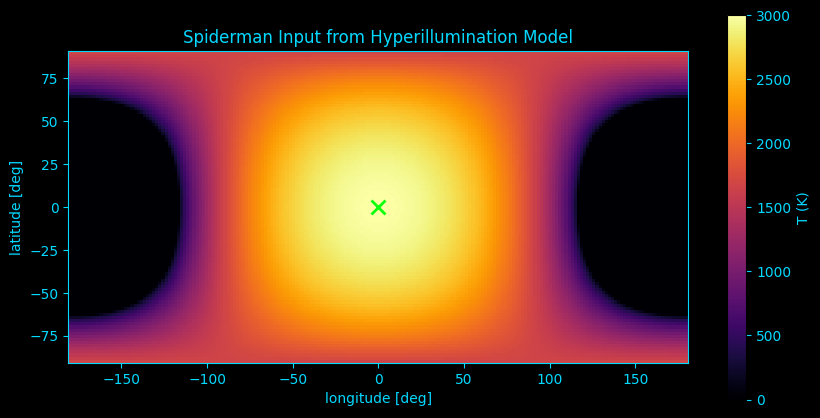

In [5]:
bg, tc = "black", "#04d9ff"   # same dark theme as plot_insolmap(..., theme='black')

fig, ax = plt.subplots(figsize=(10, 5), facecolor=bg)
im = ax.pcolormesh(lo, la, temp_grid, cmap=plt.cm.inferno, shading="auto")   # same colormap as plot_insolmap
ax.plot(0, 0, "x", color="#0cff0c", ms=10, mew=2)   # substellar point, same marker convention as spiderman's plot_square
ax.set_aspect("equal")
ax.set_facecolor(bg)
ax.set_xlabel("longitude [deg]", color=tc)
ax.set_ylabel("latitude [deg]", color=tc)
ax.tick_params(colors=tc)
for spine in ax.spines.values():
    spine.set_color(tc)

cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(colors=tc)
cbar.set_label("T (K)", color=tc)

ax.set_title("Spiderman Input from Hyperillumination Model", color=tc)
plt.show()

### SPIDERMAN phase curve from the custom brightness map (`direct_T`)

In [6]:
t_kopal, thermal_phasecurve_kopal, thermal_fp_kopal, spider_params_kopal = hipc.thermal_PhaseCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="kopal")
t_naive, thermal_phasecurve_naive, thermal_fp_naive, spider_params_naive = hipc.thermal_PhaseCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="naive")

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


#### Brightness Maps

/opt/anaconda3/envs/PhaseCurves/lib/python3.11/site-packages/spiderman/plot.py:133: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 924.855x800 with 5 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(mycax, cax=cbar_ax)


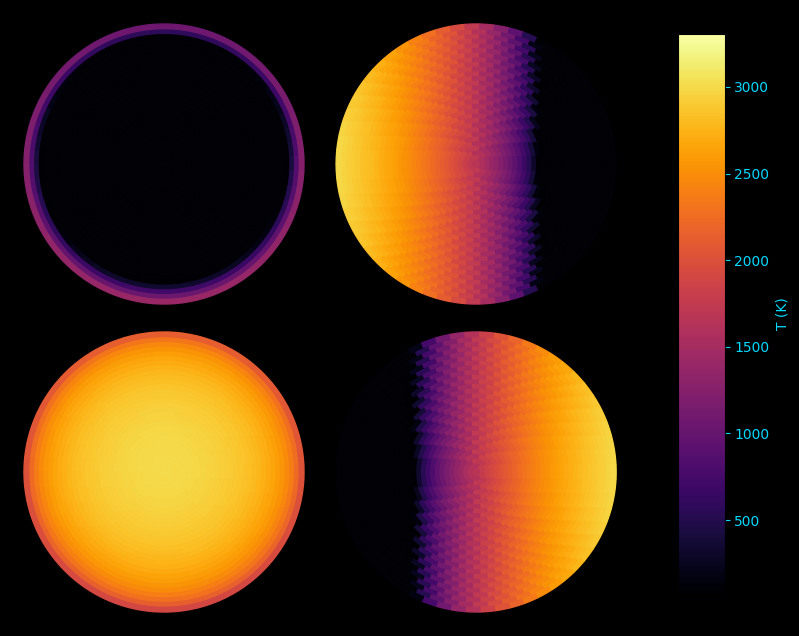

In [7]:
spider_params_kopal.plot_quad(temp_map=True,theme='black')
plt.show()

# phase = 0.25
# spider_params_kopal.plot_planet(phase,use_phase=True,temp_map=True, theme='black')
# plt.show()

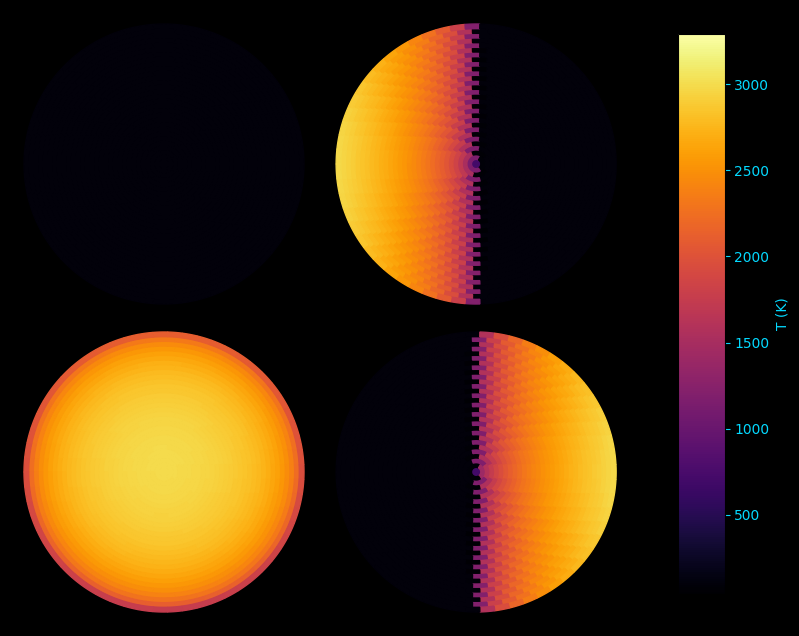

In [8]:
spider_params_naive.plot_quad(temp_map=True,theme='black')
plt.show()

# phase = 0.25
# phase_curve_naive.plot_planet(phase,use_phase=True,temp_map=True, theme='black')
# plt.show()

Slight asymmetry at phase=0 caused by incl = 86.3.

#### Phase Curve

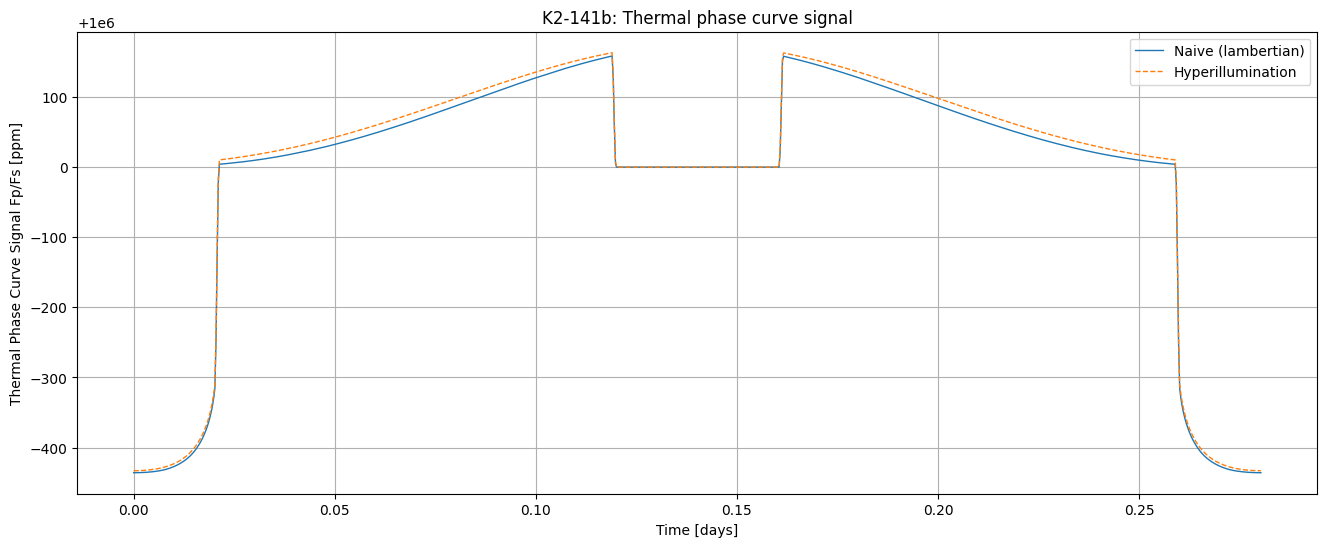

Occultation depth with Hyperillumination: 174.9 ppm   (measured: fp = 142 ppm at 4.5 um)
Occultation depth without Hyperillumination: 173.9 ppm   (measured: fp = 142 ppm at 4.5 um)


In [9]:
plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_phasecurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, thermal_phasecurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Phase Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal phase curve signal")
plt.legend()
plt.grid()
plt.show()

print(f"Occultation depth with Hyperillumination: {thermal_fp_kopal*1e6:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")
print(f"Occultation depth without Hyperillumination: {thermal_fp_naive*1e6:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


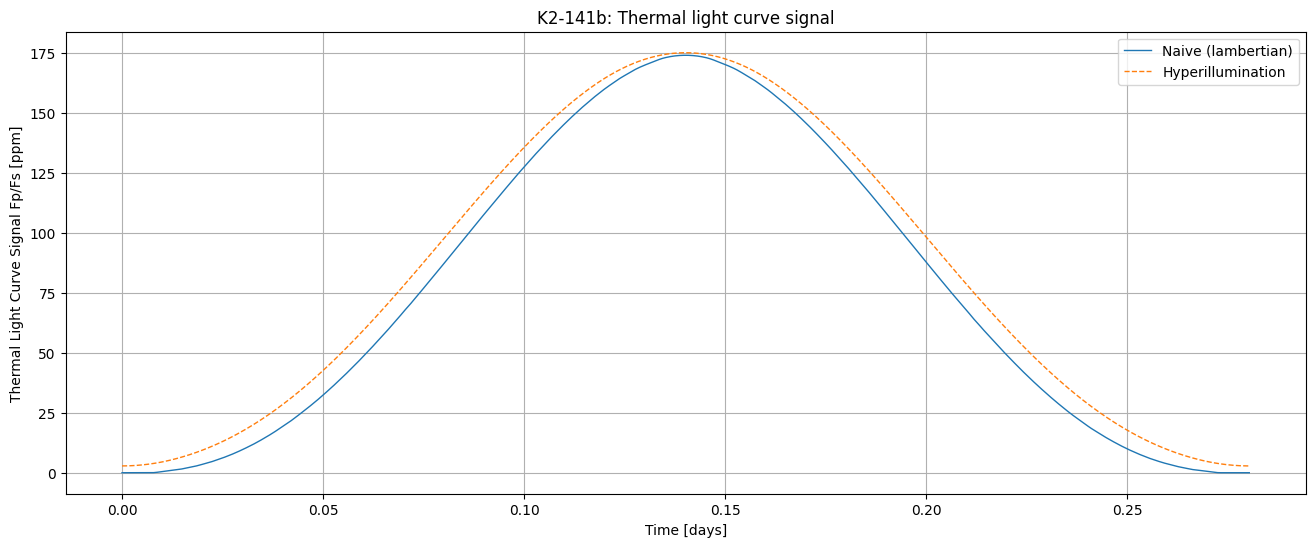

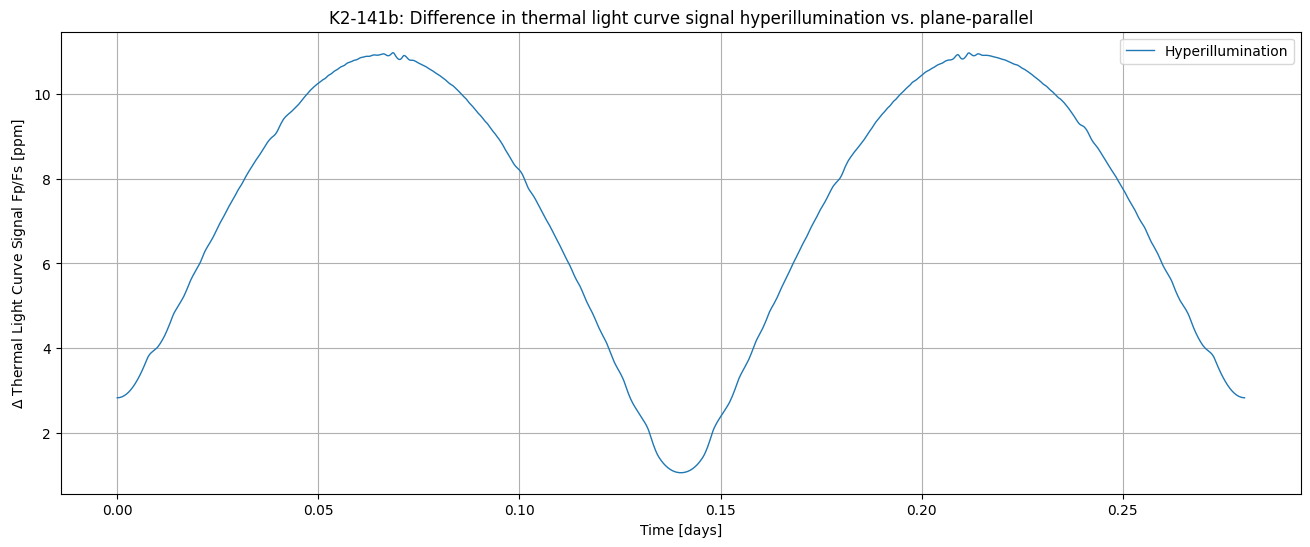

In [14]:
t_kopal, thermal_lightcurve_kopal, _ = hipc.thermal_LightCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="kopal")
t_naive, thermal_lightcurve_naive, _ = hipc.thermal_LightCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="naive")

plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_lightcurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, thermal_lightcurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal light curve signal")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()
plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, (thermal_lightcurve_kopal-thermal_lightcurve_naive)*1e6, linewidth=1, label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in thermal light curve signal hyperillumination vs. plane-parallel")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()

In [11]:
#TODO Argue why this is bigger than 142ppm (different wavelength range, albedo, ...)?

In [12]:
#TODO compare with naive model in same pipeline. Is there a standard spiderman model doing the same? Eg Zhang without offset?